# Customer Segmentation Using RFM Analysis

## Project Overview

This project uses RFM (Recency, Frequency, Monetary) analysis to segment customers based on their purchasing behaviour.

The Online Retail dataset is used to identify customer groups, understand purchasing patterns, analyze revenue contribution, and develop targeted marketing recommendations.

## Project Objectives

1. Clean and prepare the customer transaction dataset.
2. Calculate Recency, Frequency, and Monetary values.
3. Segment customers based on their RFM scores.
4. Analyze customer behaviour and revenue contribution.
5. Visualize customer segments and purchasing trends.
6. Recommend marketing strategies for different customer segments.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [77]:
# Load the Excel dataset

df = pd.read_excel("../Dataset/Online Retail.xlsx")

# Display first five rows

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [78]:
# Check number of rows and columns

df.shape

(541909, 8)

In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [80]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [81]:
# Check missing values in each column

df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [82]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [83]:
# Check duplicate records

df.duplicated().sum()

np.int64(5268)

In [84]:
# Create a working copy of original dataset

df_clean = df.copy()

# Remove exact duplicate records

df_clean = df_clean.drop_duplicates()

# Check remaining rows

df_clean.shape

(536641, 8)

In [85]:
# Identify cancelled invoices

cancelled_invoices = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Count cancelled invoice rows

cancelled_invoices.shape

(9251, 8)

In [86]:
# Count negative quantity records

(df_clean["Quantity"] < 0).sum()

np.int64(10587)

In [87]:
# Display first five cancelled invoice records

cancelled_invoices.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [88]:
# Identify all negative quantity records

negative_quantity = df_clean[
    df_clean["Quantity"] < 0
]

# Display first 10 records

negative_quantity.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [89]:
# Check zero or negative unit prices

(df_clean["UnitPrice"] <= 0).sum()

np.int64(2512)

In [90]:
# Count zero-price records

(df_clean["UnitPrice"] == 0).sum()

np.int64(2510)

In [91]:
# Count negative-price records

(df_clean["UnitPrice"] < 0).sum()

np.int64(2)

In [92]:
# Display negative-price transactions

negative_prices = df_clean[df_clean["UnitPrice"] < 0]

negative_prices

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [93]:
# Display first 10 zero-price transactions

zero_price = df_clean[df_clean["UnitPrice"] == 0]

zero_price.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [94]:
# Check missing values in zero-price records

zero_price.isnull().sum()

InvoiceNo         0
StockCode         0
Description    1454
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     2470
Country           0
dtype: int64

In [95]:
# Count zero-price records with CustomerID

zero_price["CustomerID"].notnull().sum()

np.int64(40)

In [96]:
# Check quantity distribution in zero-price records

zero_price["Quantity"].value_counts().head(10)

Quantity
 1    398
 2    129
 3     84
-1     79
-2     58
-5     46
 4     42
 5     40
-3     39
-6     36
Name: count, dtype: int64

In [97]:
# Display zero-price transactions with CustomerID

zero_price_customers = zero_price[
    zero_price["CustomerID"].notnull()
]

zero_price_customers

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [98]:
# Get invoice numbers of zero-price customer transactions

zero_invoice_numbers = zero_price_customers["InvoiceNo"].unique()

# Find all transaction lines belonging to these invoices

related_invoices = df_clean[
    df_clean["InvoiceNo"].isin(zero_invoice_numbers)
]

# Calculate total sales for each invoice

invoice_sales = (
    related_invoices.assign(
        Sales=related_invoices["Quantity"] * related_invoices["UnitPrice"]
    )
    .groupby("InvoiceNo")["Sales"]
    .sum()
)

invoice_sales.head(20)

InvoiceNo
537197     286.50
539263     332.18
539722     762.30
540372    3527.64
541109      14.95
543599       0.00
547417     329.56
548318     453.05
548871      91.48
550188     669.25
553000      62.12
554037     766.36
561284      87.96
561669     811.90
561916     250.00
562973    1234.00
564651       0.00
568158    1146.80
568384       0.00
569716     223.22
Name: Sales, dtype: float64

In [99]:
# Find invoices with zero total sales

zero_sales_invoices = invoice_sales[
    invoice_sales == 0
]

zero_sales_invoices

InvoiceNo
543599    0.0
564651    0.0
568384    0.0
578841    0.0
Name: Sales, dtype: float64

In [100]:
# Count invoices with positive sales

(invoice_sales > 0).sum()

np.int64(30)

In [101]:
(invoice_sales == 0).sum()

np.int64(4)

In [102]:
(invoice_sales < 0).sum()

np.int64(0)

In [103]:
related_invoices[
    related_invoices["InvoiceNo"].isin(zero_sales_invoices.index)
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
314745,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314746,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314747,564651,22955,36 FOIL STAR CAKE CASES,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands
314748,564651,21786,POLKADOT RAIN HAT,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands
361825,568384,M,Manual,1,2011-09-27 09:46:00,0.0,12748.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.0,13256.0,United Kingdom


In [105]:
# Create a copy of the deduplicated dataset

rfm_data = df_clean.copy()

# Remove records without CustomerID

rfm_data = rfm_data.dropna(subset=["CustomerID"])

# Remove cancelled invoices

rfm_data = rfm_data[
    ~rfm_data["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities

rfm_data = rfm_data[rfm_data["Quantity"] > 0]

# Keep only positive unit prices

rfm_data = rfm_data[rfm_data["UnitPrice"] > 0]

# Check final dataset dimensions

rfm_data.shape

(392692, 8)

In [106]:
# Calculate sales revenue for each transaction

rfm_data["Sales"] = (
    rfm_data["Quantity"] * rfm_data["UnitPrice"]
)

# Display first five records

rfm_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [109]:
# Calculate total revenue

total_revenue = rfm_data["Sales"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 8887208.89


In [110]:
# Total unique customers

total_customers = rfm_data["CustomerID"].nunique()

# Total unique invoices

total_invoices = rfm_data["InvoiceNo"].nunique()

# Total transaction records

total_transactions = len(rfm_data)

print("Total Customers:", total_customers)
print("Total Invoices:", total_invoices)
print("Total Transactions:", total_transactions)

Total Customers: 4338
Total Invoices: 18532
Total Transactions: 392692


In [111]:
# Find latest transaction date

latest_date = rfm_data["InvoiceDate"].max()

# Set reference date

reference_date = latest_date + pd.Timedelta(days=1)

print("Latest Transaction Date:", latest_date)
print("Reference Date:", reference_date)

Latest Transaction Date: 2011-12-09 12:50:00
Reference Date: 2011-12-10 12:50:00


In [112]:
# Find last purchase date for each customer

customer_last_purchase = (
    rfm_data.groupby("CustomerID")["InvoiceDate"]
    .max()
    .reset_index()
)

# Rename columns

customer_last_purchase.columns = [
    "CustomerID", "LastPurchaseDate"
]

# Display first five customers

customer_last_purchase.head()

,CustomerID,LastPurchaseDate
0,12346.0,2011-01-18 10:01:00
1,12347.0,2011-12-07 15:52:00
2,12348.0,2011-09-25 13:13:00
3,12349.0,2011-11-21 09:51:00
4,12350.0,2011-02-02 16:01:00


In [113]:
# Calculate Recency in days

customer_last_purchase["Recency"] = (
    reference_date -
    customer_last_purchase["LastPurchaseDate"]
).dt.days

# Display first 10 customers

customer_last_purchase.head(10)

,CustomerID,LastPurchaseDate,Recency
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,310
5,12352.0,2011-11-03 14:37:00,36
6,12353.0,2011-05-19 17:47:00,204
7,12354.0,2011-04-21 13:11:00,232
8,12355.0,2011-05-09 13:49:00,214
9,12356.0,2011-11-17 08:40:00,23


In [114]:
# Calculate number of unique invoices per customer

customer_frequency = (
    rfm_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index()
)

# Rename columns

customer_frequency.columns = [
    "CustomerID", "Frequency"
]

# Display first 10 customers

customer_frequency.head(10)

,CustomerID,Frequency
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
5,12352.0,8
6,12353.0,1
7,12354.0,1
8,12355.0,1
9,12356.0,3


In [115]:
# Calculate total spending per customer

customer_monetary = (
    rfm_data.groupby("CustomerID")["Sales"]
    .sum()
    .reset_index()
)

# Rename columns

customer_monetary.columns = [
    "CustomerID", "Monetary"
]

# Display first 10 customers

customer_monetary.head(10)

,CustomerID,Monetary
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
5,12352.0,2506.04
6,12353.0,89.00
7,12354.0,1079.40
8,12355.0,459.40
9,12356.0,2811.43


In [116]:
# Merge Recency and Frequency

rfm = customer_last_purchase.merge(
    customer_frequency,
    on="CustomerID"
)

# Merge Monetary

rfm = rfm.merge(
    customer_monetary,
    on="CustomerID"
)

# Keep only required RFM columns

rfm = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
]

# Display first 10 customers

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


In [117]:
# Assign RFM scores using quintiles

rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
)

# Display results

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,326,1,77183.60,1,1,5
1,12347.0,2,7,4310.00,5,5,5
2,12348.0,75,4,1797.24,2,4,4
3,12349.0,19,1,1757.55,4,1,4
4,12350.0,310,1,334.40,1,1,2
5,12352.0,36,8,2506.04,3,5,5
6,12353.0,204,1,89.00,1,1,1
7,12354.0,232,1,1079.40,1,1,4
8,12355.0,214,1,459.40,1,1,2
9,12356.0,23,3,2811.43,4,3,5


In [118]:
# Create combined RFM score

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Display customer scores

rfm[
    ["CustomerID", "R_Score", "F_Score",
     "M_Score", "RFM_Score"]
].head(10)

,CustomerID,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,1,1,5,115
1,12347.0,5,5,5,555
2,12348.0,2,4,4,244
3,12349.0,4,1,4,414
4,12350.0,1,1,2,112
5,12352.0,3,5,5,355
6,12353.0,1,1,1,111
7,12354.0,1,1,4,114
8,12355.0,1,1,2,112
9,12356.0,4,3,5,435


In [119]:
# Create customer segments

def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["F_Score"] >= 4 and row["M_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] >= 2:
        return "Potential Loyalists"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"

    else:
        return "Others"


# Apply segmentation

rfm["Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Display customer segments

rfm[["CustomerID", "RFM_Score", "Segment"]].head(20)

,CustomerID,RFM_Score,Segment
0,12346.0,115,Lost Customers
1,12347.0,555,Champions
2,12348.0,244,Loyal Customers
3,12349.0,414,Recent Customers
4,12350.0,112,Lost Customers
5,12352.0,355,Loyal Customers
6,12353.0,111,Lost Customers
7,12354.0,114,Lost Customers
8,12355.0,112,Lost Customers
9,12356.0,435,Potential Loyalists


In [120]:
# Count customers in each segment

segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Lost Customers         1065
Champions               957
Loyal Customers         693
Others                  553
Potential Loyalists     526
At Risk                 403
Recent Customers        141
Name: count, dtype: int64


In [121]:
# Calculate percentage of customers in each segment

segment_percentage = (
    rfm["Segment"].value_counts(normalize=True) * 100
)

print(segment_percentage.round(2))

Segment
Lost Customers         24.55
Champions              22.06
Loyal Customers        15.98
Others                 12.75
Potential Loyalists    12.13
At Risk                 9.29
Recent Customers        3.25
Name: proportion, dtype: float64


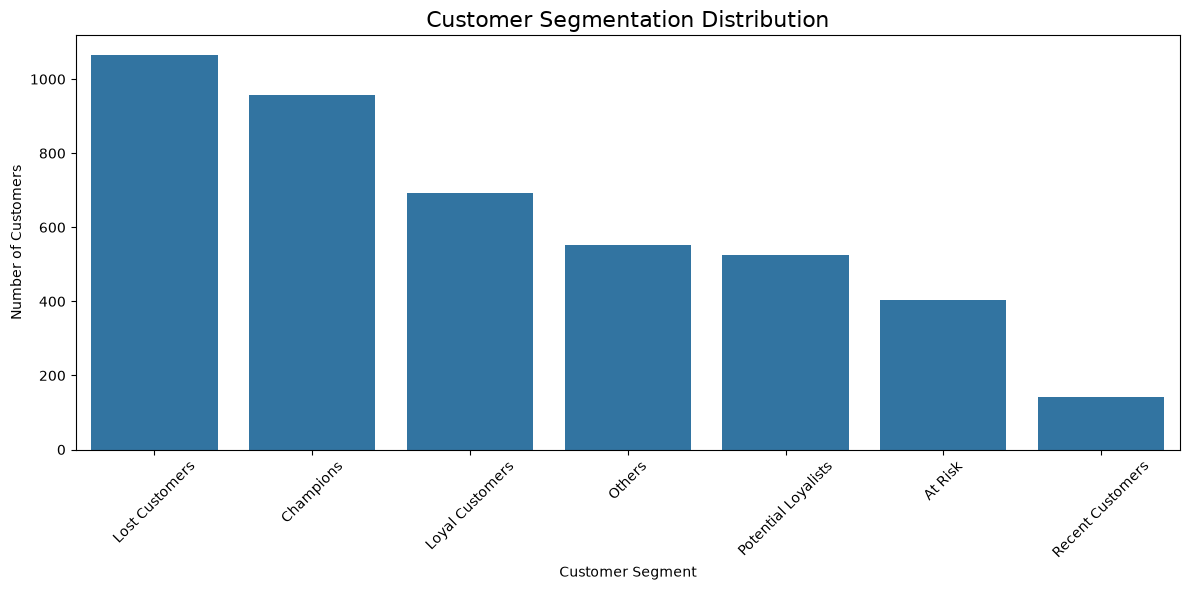

In [122]:
# Customer segmentation bar chart

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title(
    "Customer Segmentation Distribution",
    fontsize=16
)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

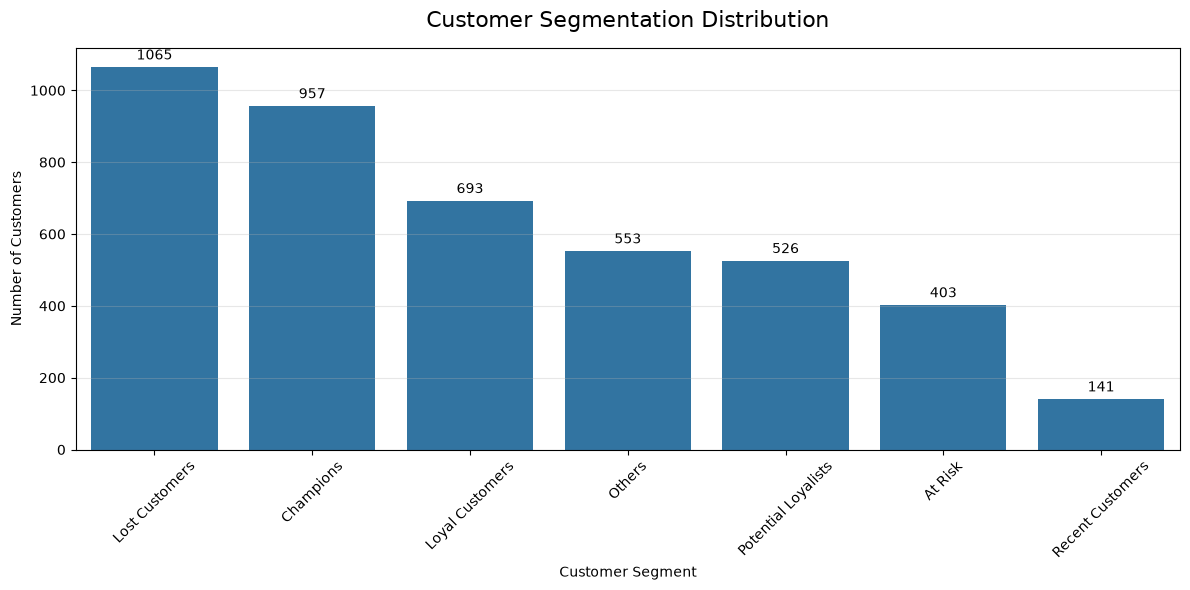

In [123]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

# Add data labels

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Customer Segmentation Distribution",
          fontsize=16, pad=15)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

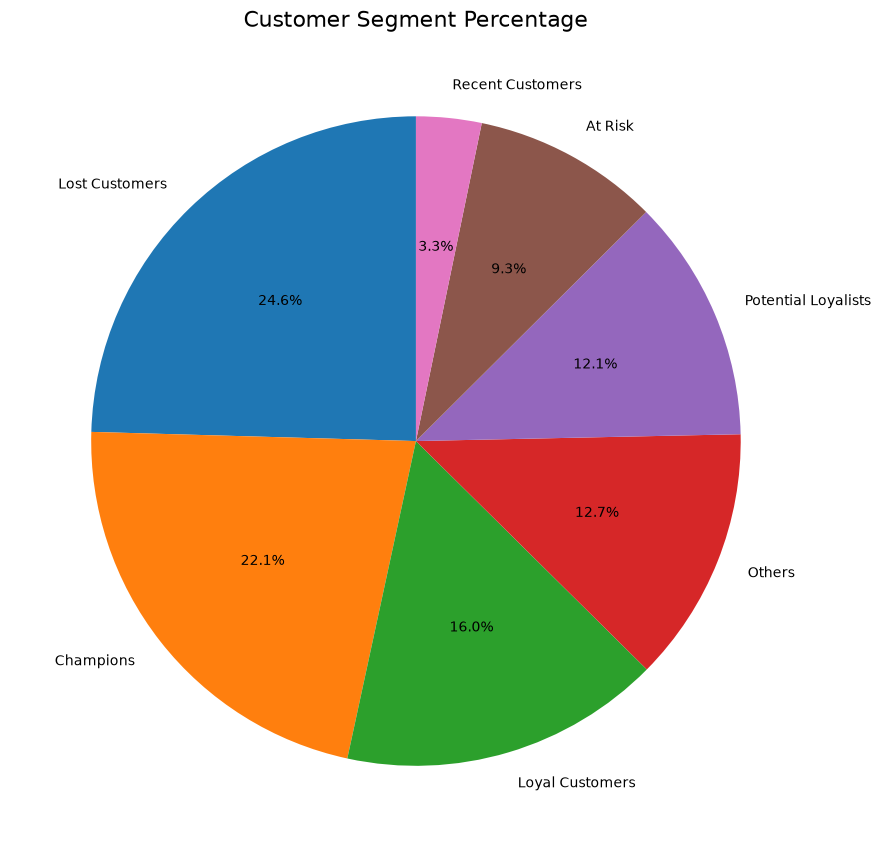

In [124]:
plt.figure(figsize=(9, 9))

plt.pie(
    segment_percentage,
    labels=segment_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Customer Segment Percentage",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [125]:
# Calculate revenue by customer segment

segment_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_revenue.round(2))

Segment
Champions              5791640.74
Loyal Customers        1298467.95
Potential Loyalists     519252.99
Lost Customers          518322.15
At Risk                 377513.21
Others                  330860.21
Recent Customers         51151.64
Name: Monetary, dtype: float64


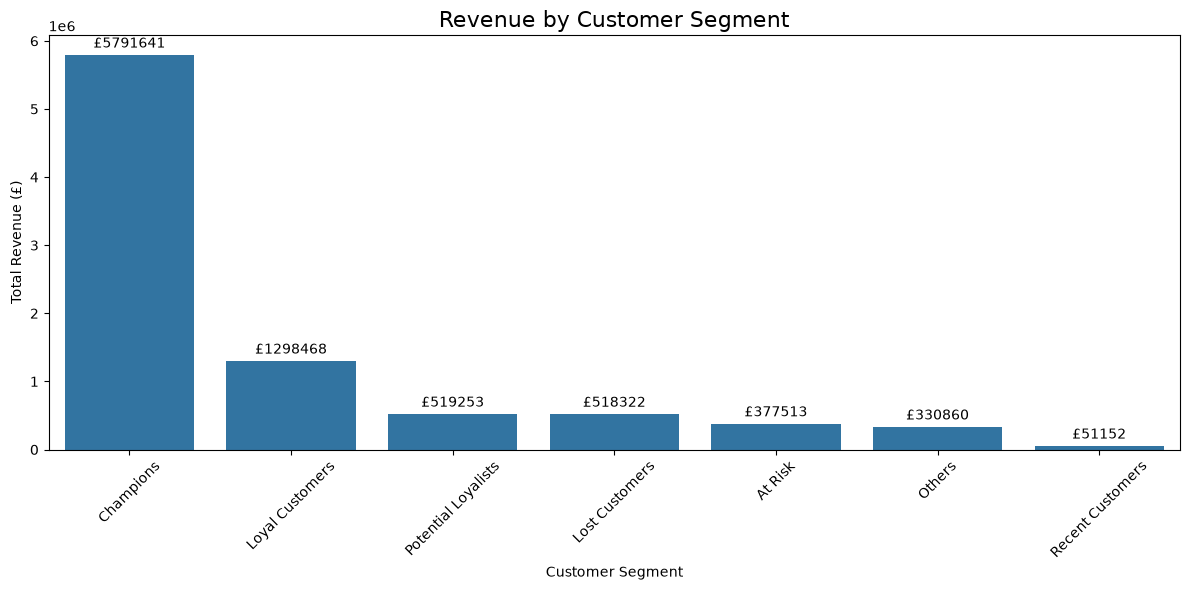

In [126]:
# Revenue by customer segment

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=segment_revenue.index,
    y=segment_revenue.values
)

# Add revenue labels

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="£%.0f",
        padding=3
    )

plt.title("Revenue by Customer Segment", fontsize=16)

plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue (£)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

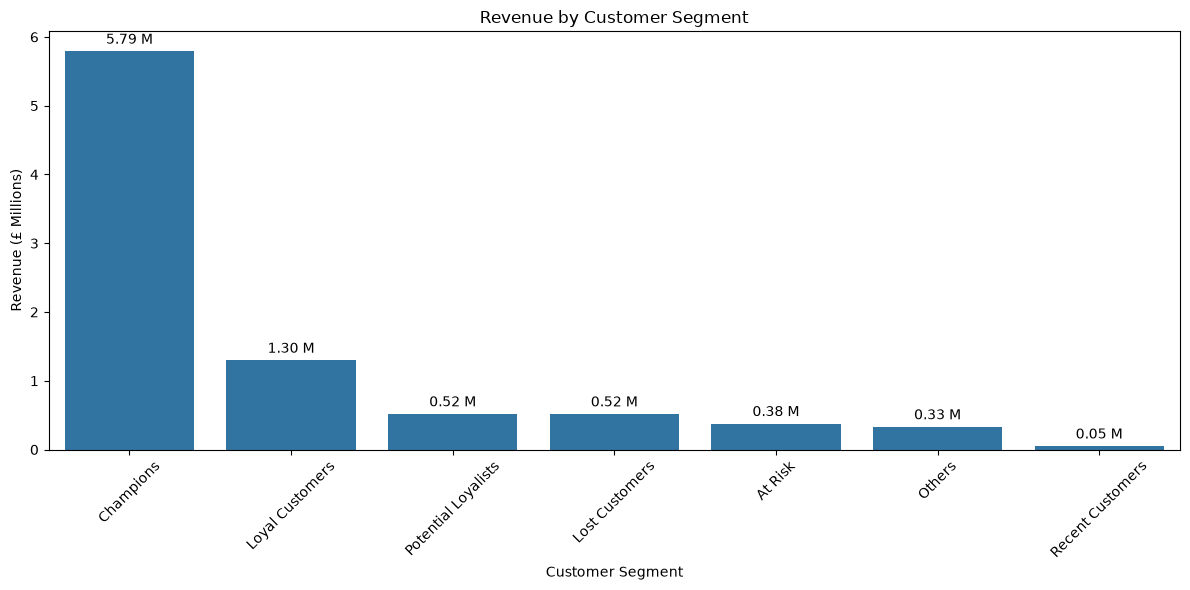

In [127]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=segment_revenue.index,
    y=segment_revenue.values / 1000000
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f M",
        padding=3
    )

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£ Millions)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [128]:
# Calculate average revenue per customer

segment_avg_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .mean()
    .sort_values(ascending=False)
)

print(segment_avg_revenue.round(2))

Segment
Champions              6051.87
Loyal Customers        1873.69
Potential Loyalists     987.17
At Risk                 936.76
Others                  598.30
Lost Customers          486.69
Recent Customers        362.78
Name: Monetary, dtype: float64


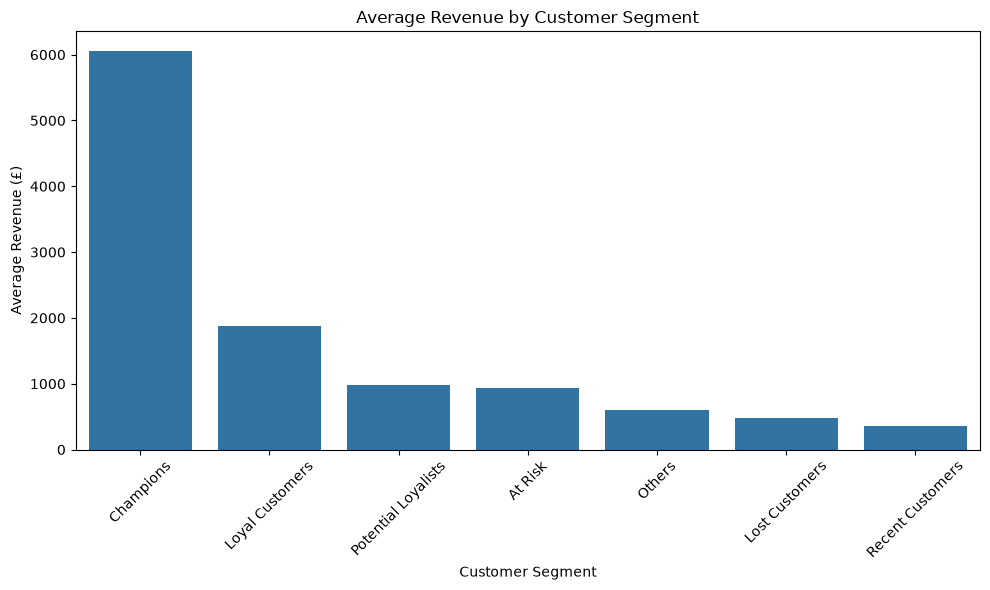

In [129]:
# Average revenue by customer segment

plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_avg_revenue.index,
    y=segment_avg_revenue.values
)

plt.title("Average Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [130]:
# Calculate average purchase frequency by segment

segment_frequency = (
    rfm.groupby("Segment")["Frequency"]
    .mean()
    .sort_values(ascending=False)
)

print(segment_frequency.round(2))

Segment
Champions              11.12
Loyal Customers         5.19
At Risk                 2.41
Potential Loyalists     2.11
Others                  1.62
Lost Customers          1.10
Recent Customers        1.00
Name: Frequency, dtype: float64


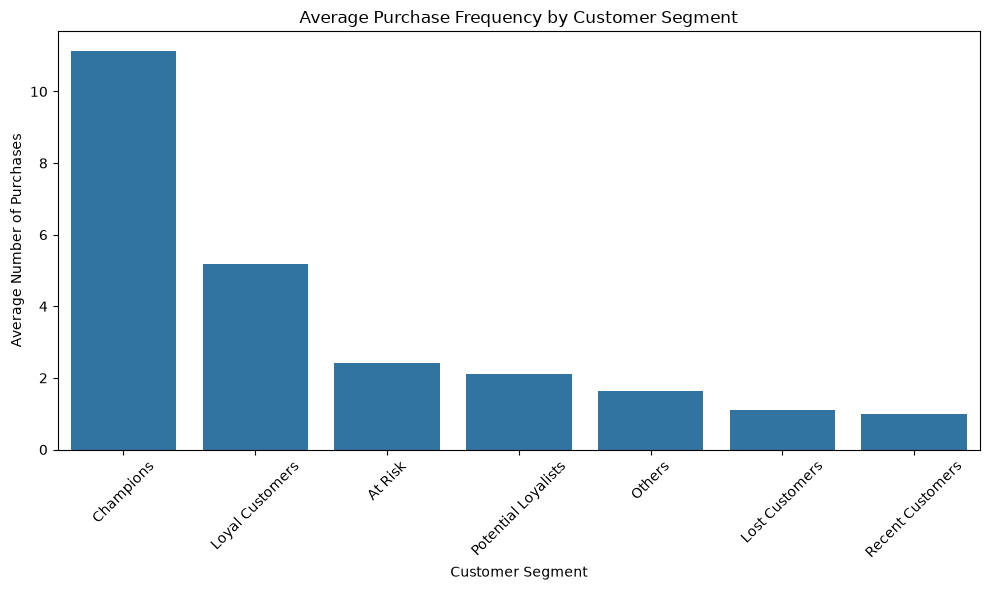

In [131]:
# Visualize average purchase frequency

plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_frequency.index,
    y=segment_frequency.values
)

plt.title("Average Purchase Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Purchases")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [132]:
# Calculate average recency by customer segment

segment_recency = (
    rfm.groupby("Segment")["Recency"]
    .mean()
    .sort_values(ascending=True)
)

print(segment_recency.round(2))

Segment
Champions               12.82
Potential Loyalists     16.89
Recent Customers        18.50
Others                  53.44
Loyal Customers         71.80
At Risk                164.49
Lost Customers         217.90
Name: Recency, dtype: float64


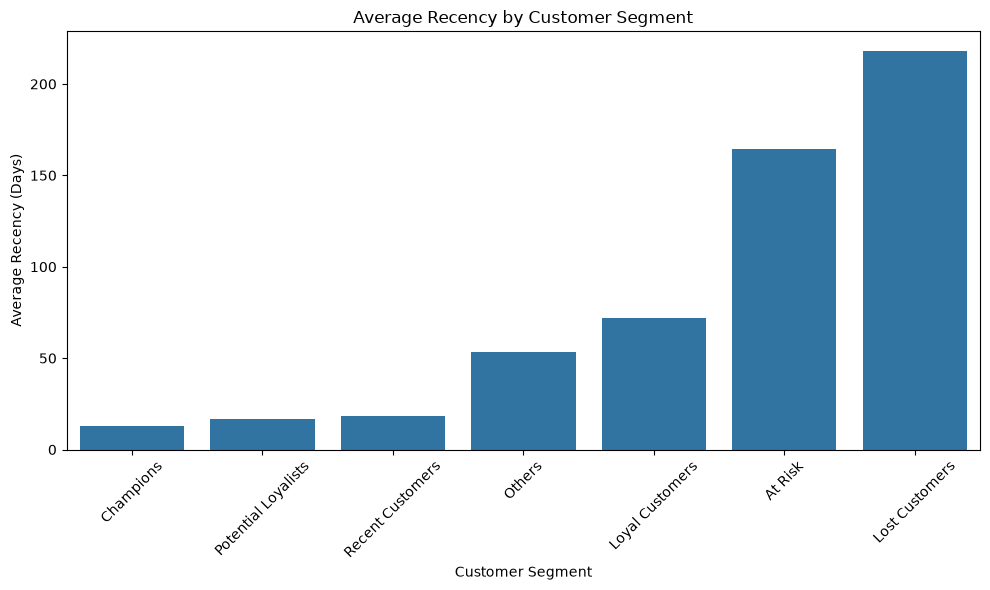

In [133]:
# Visualize average recency by customer segment

plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_recency.index,
    y=segment_recency.values
)

plt.title("Average Recency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Recency (Days)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [134]:
# Calculate revenue generated by each customer

top_customers = (
    rfm_data.groupby("CustomerID")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers.round(2))

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Sales, dtype: float64


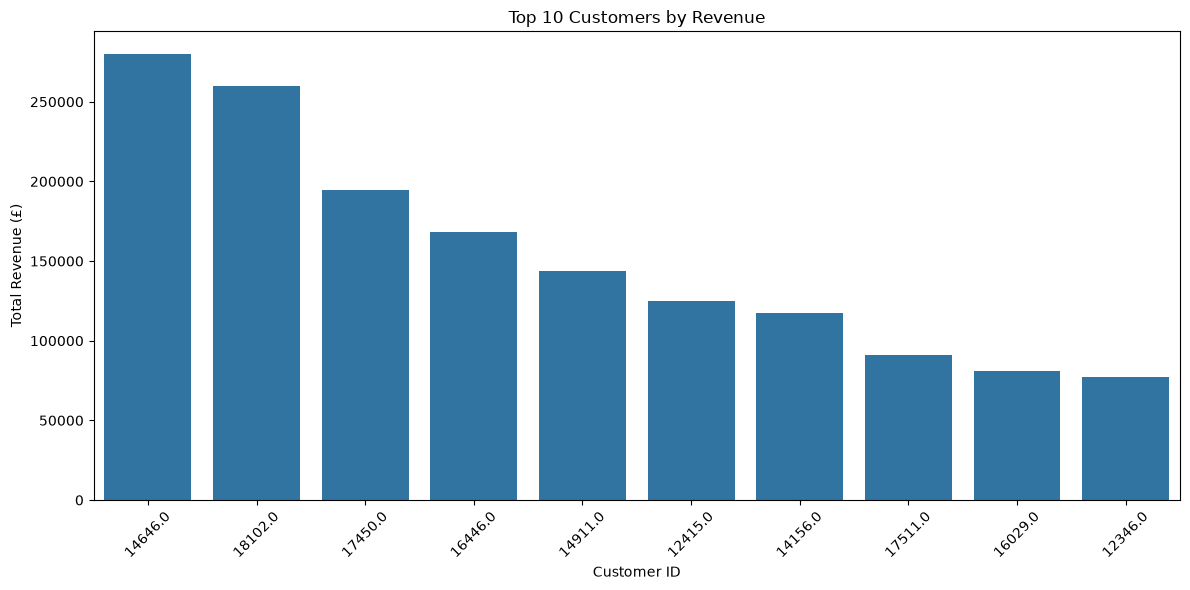

In [135]:
# Visualize top 10 customers by revenue

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_customers.index.astype(str),
    y=top_customers.values
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

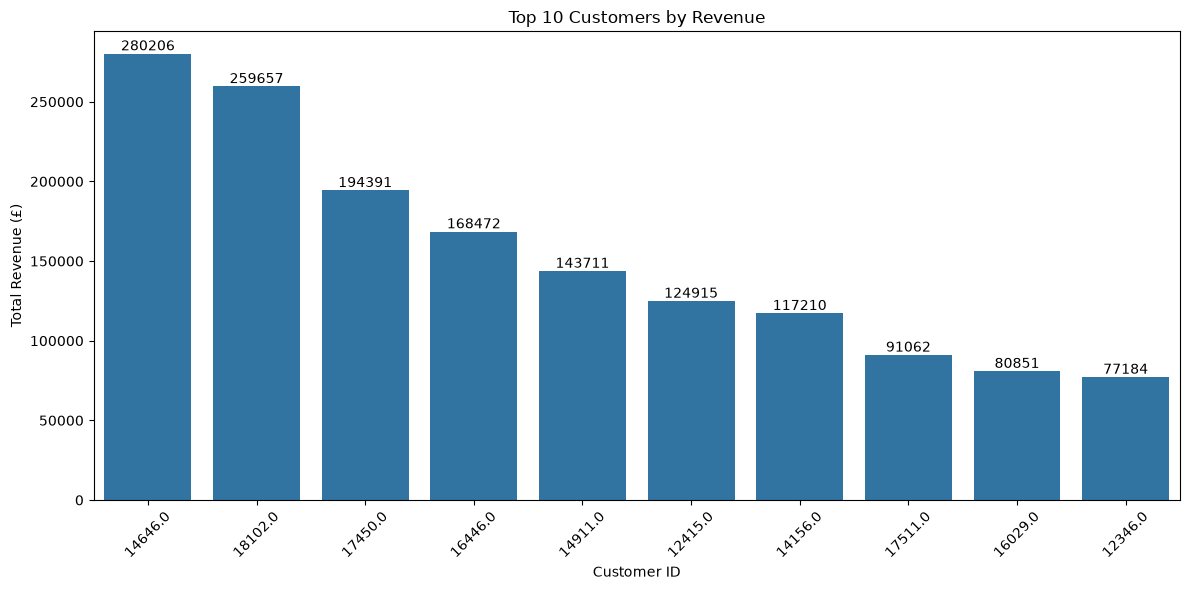

In [136]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_customers.index.astype(str),
    y=top_customers.values
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

In [137]:
# Calculate revenue by country

country_revenue = (
    rfm_data.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 countries

print(country_revenue.head(10).round(2))

Country
United Kingdom    7285024.64
Netherlands        285446.34
EIRE               265262.46
Germany            228678.40
France             208934.31
Australia          138453.81
Spain               61558.56
Switzerland         56443.95
Belgium             41196.34
Sweden              38367.83
Name: Sales, dtype: float64


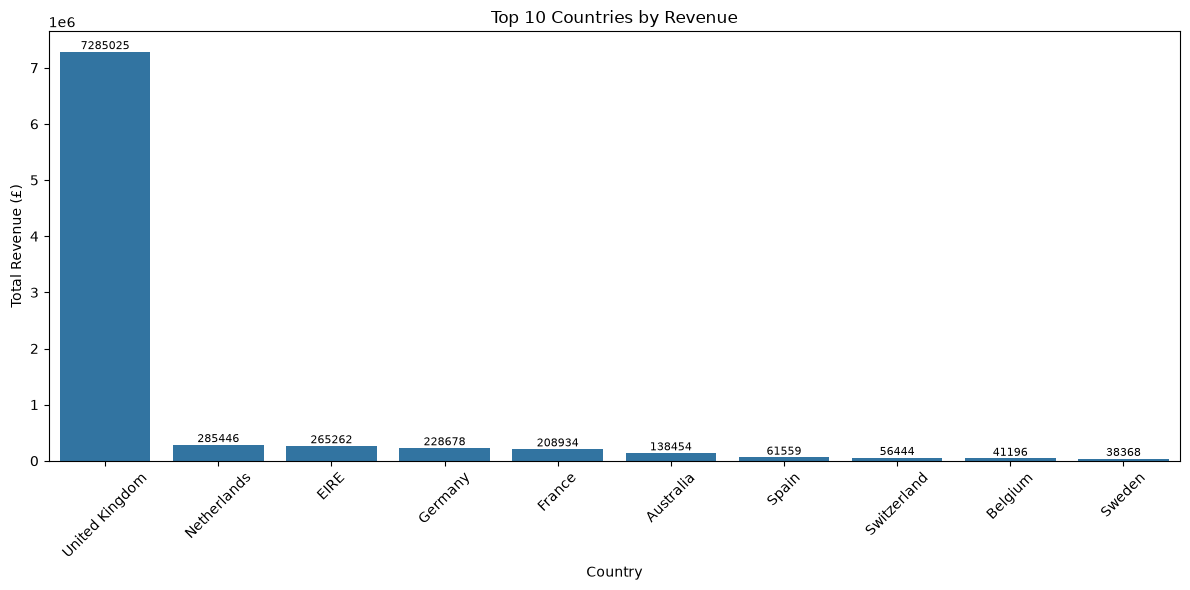

In [138]:
# Visualize top 10 countries by revenue

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=country_revenue.head(10).index,
    y=country_revenue.head(10).values
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=8)

plt.tight_layout()
plt.show()

In [139]:
# Extract month and year from InvoiceDate

rfm_data["YearMonth"] = (
    rfm_data["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly revenue

monthly_sales = (
    rfm_data.groupby("YearMonth")["Sales"]
    .sum()
)

# Display monthly sales

print(monthly_sales)

YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Sales, dtype: float64


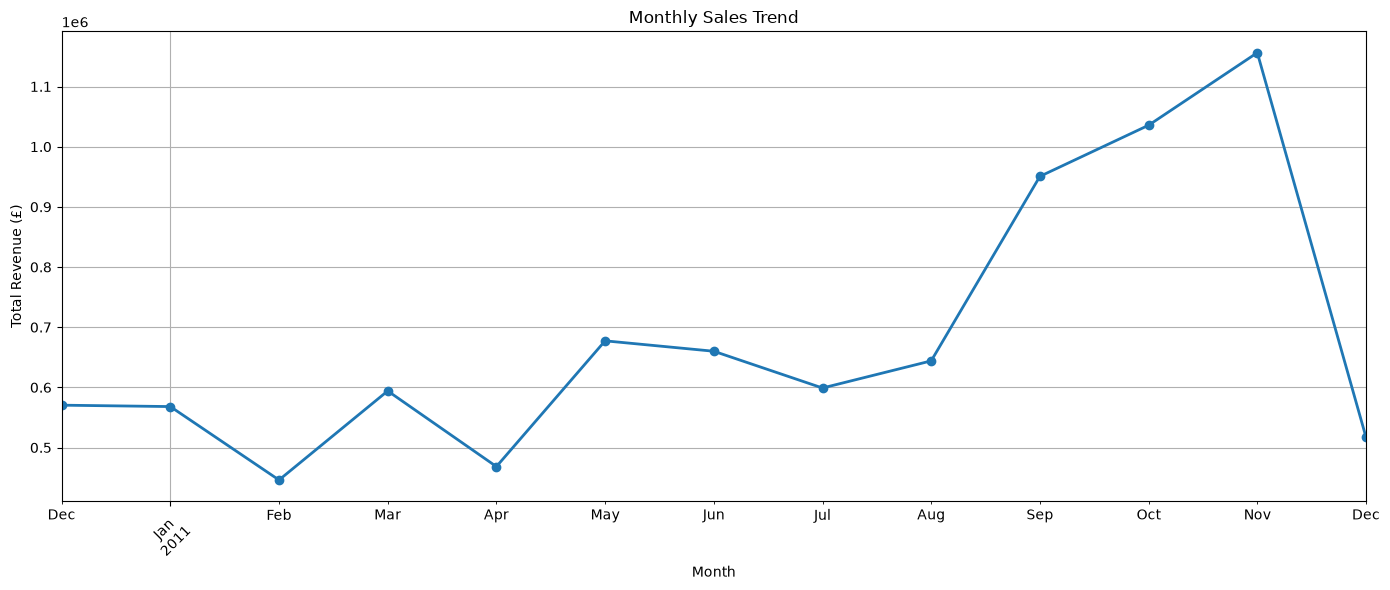

In [140]:
# Monthly Sales Trend

plt.figure(figsize=(14, 6))

monthly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [141]:
# Extract quarter from InvoiceDate
rfm_data["Quarter"] = rfm_data["InvoiceDate"].dt.to_period("Q")

# Calculate quarterly revenue
quarterly_sales = (
    rfm_data.groupby("Quarter")["Sales"]
    .sum()
)

print(quarterly_sales.round(2))

Quarter
2010Q4     570422.73
2011Q1    1608267.99
2011Q2    1805775.53
2011Q3    2193704.14
2011Q4    2709038.50
Freq: Q-DEC, Name: Sales, dtype: float64


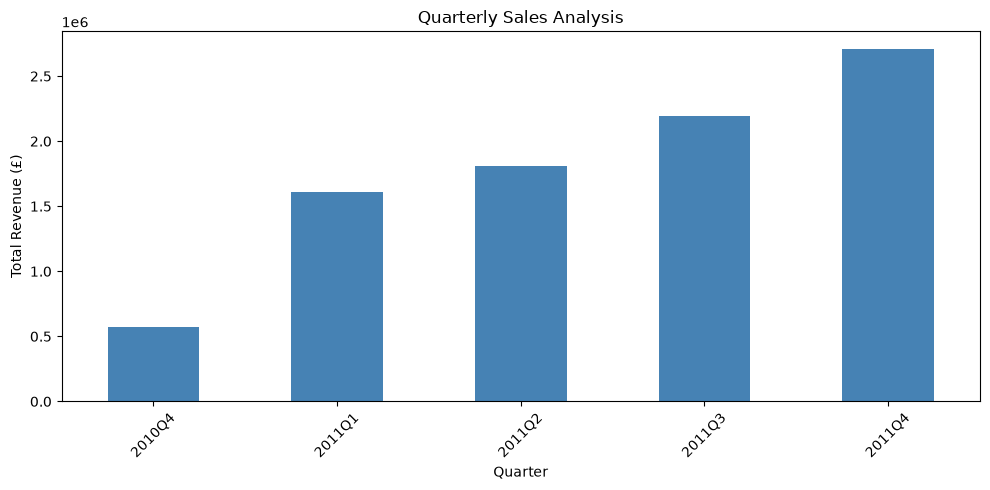

In [142]:
# Quarterly Sales Trend

plt.figure(figsize=(10, 5))

quarterly_sales.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Quarterly Sales Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [143]:
# Extract year from InvoiceDate
rfm_data["Year"] = rfm_data["InvoiceDate"].dt.year

# Calculate yearly revenue
yearly_sales = (
    rfm_data.groupby("Year")["Sales"]
    .sum()
)

print(yearly_sales.round(2))

Year
2010     570422.73
2011    8316786.16
Name: Sales, dtype: float64


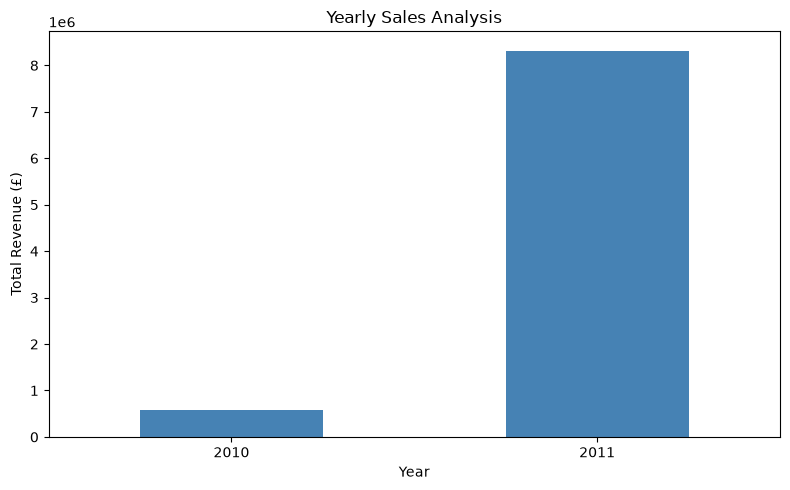

In [144]:
# Yearly Sales Analysis

plt.figure(figsize=(8, 5))

yearly_sales.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Yearly Sales Analysis")
plt.xlabel("Year")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [145]:
# Calculate top 10 best-selling products

top_products = (
    rfm_data.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


In [146]:
# Calculate top 10 products by revenue

product_revenue = (
    rfm_data.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(product_revenue.round(2))

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Sales, dtype: float64


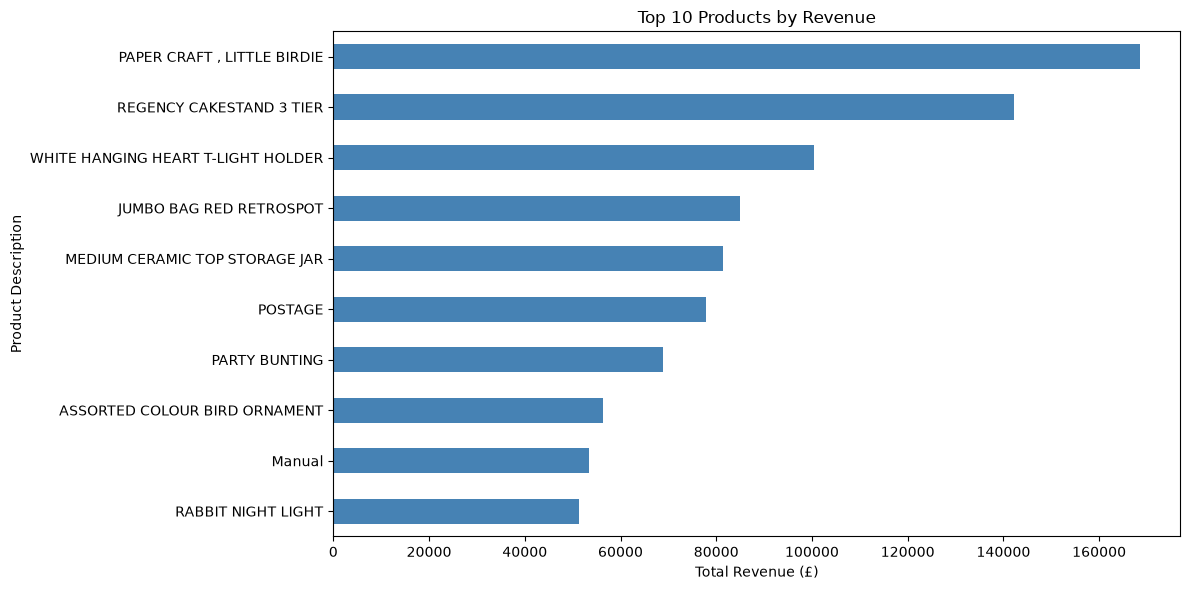

In [147]:
# Visualize top 10 products by revenue

plt.figure(figsize=(12, 6))

product_revenue.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Product Description")

plt.tight_layout()
plt.show()

In [148]:

# Marketing recommendations for each customer segment

marketing_recommendations = {
    "Champions": "Offer VIP rewards and exclusive benefits",
    
    "Loyal Customers": "Provide loyalty points and membership offers",
    
    "Potential Loyalists": "Send personalized product recommendations",
    
    "Recent Customers": "Provide welcome offers and encourage repeat purchases",
    
    "At Risk": "Send special discounts to encourage customers to return",
    
    "Lost Customers": "Launch win-back email campaigns",
    
    "Others": "Provide targeted promotions based on purchase history"
}

# Add recommendations to the RFM dataset

rfm["Recommendation"] = rfm["Segment"].map(
    marketing_recommendations
)

# Display customer segments and recommendations

rfm[[
    "CustomerID",
    "Segment",
    "Recency",
    "Frequency",
    "Monetary",
    "Recommendation"
]].head(10)


,CustomerID,Segment,Recency,Frequency,Monetary,Recommendation
0,12346.0,Lost Customers,326,1,77183.60,Launch win-back email campaigns
1,12347.0,Champions,2,7,4310.00,Offer VIP rewards and exclusive benefits
2,12348.0,Loyal Customers,75,4,1797.24,Provide loyalty points and membership offers
3,12349.0,Recent Customers,19,1,1757.55,Provide welcome offers and encourage repeat pu...
4,12350.0,Lost Customers,310,1,334.40,Launch win-back email campaigns
5,12352.0,Loyal Customers,36,8,2506.04,Provide loyalty points and membership offers
6,12353.0,Lost Customers,204,1,89.00,Launch win-back email campaigns
7,12354.0,Lost Customers,232,1,1079.40,Launch win-back email campaigns
8,12355.0,Lost Customers,214,1,459.40,Launch win-back email campaigns
9,12356.0,Potential Loyalists,23,3,2811.43,Send personalized product recommendations


In [149]:
print("CUSTOMER SEGMENTATION INSIGHTS")
print("--------------------------------")

print("Total Customers:", rfm["CustomerID"].nunique())

print("\nCustomer Count by Segment:")
print(rfm["Segment"].value_counts())

print("\nRevenue by Segment:")
print(rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False))

print("\nAverage Recency by Segment:")
print(rfm.groupby("Segment")["Recency"].mean().round(2))

CUSTOMER SEGMENTATION INSIGHTS
--------------------------------
Total Customers: 4338

Customer Count by Segment:
Segment
Lost Customers         1065
Champions               957
Loyal Customers         693
Others                  553
Potential Loyalists     526
At Risk                 403
Recent Customers        141
Name: count, dtype: int64

Revenue by Segment:
Segment
Champions              5791640.740
Loyal Customers        1298467.951
Potential Loyalists     519252.990
Lost Customers          518322.152
At Risk                 377513.211
Others                  330860.210
Recent Customers         51151.640
Name: Monetary, dtype: float64

Average Recency by Segment:
Segment
At Risk                164.49
Champions               12.82
Lost Customers         217.90
Loyal Customers         71.80
Others                  53.44
Potential Loyalists     16.89
Recent Customers        18.50
Name: Recency, dtype: float64


## Key Business Insights

1. The analysis identified 4,338 unique customers across seven customer segments.
2. Lost Customers represent the largest segment, accounting for 1,065 customers (24.55%).
3. Champions generate the highest revenue, contributing approximately £5.79 million.
4. Loyal Customers contribute approximately £1.30 million in revenue.
5. At-Risk and Lost Customers require targeted retention and win-back campaigns.
6. Potential Loyalists can be encouraged to make repeat purchases through personalized offers.

## Business Recommendations

- Offer exclusive rewards to Champions.
- Introduce loyalty programs for Loyal Customers.
- Send personalized product recommendations to Potential Loyalists.
- Use special offers to re-engage At-Risk Customers.
- Run win-back campaigns for Lost Customers.
- Welcome Recent Customers with offers that encourage a second purchase.